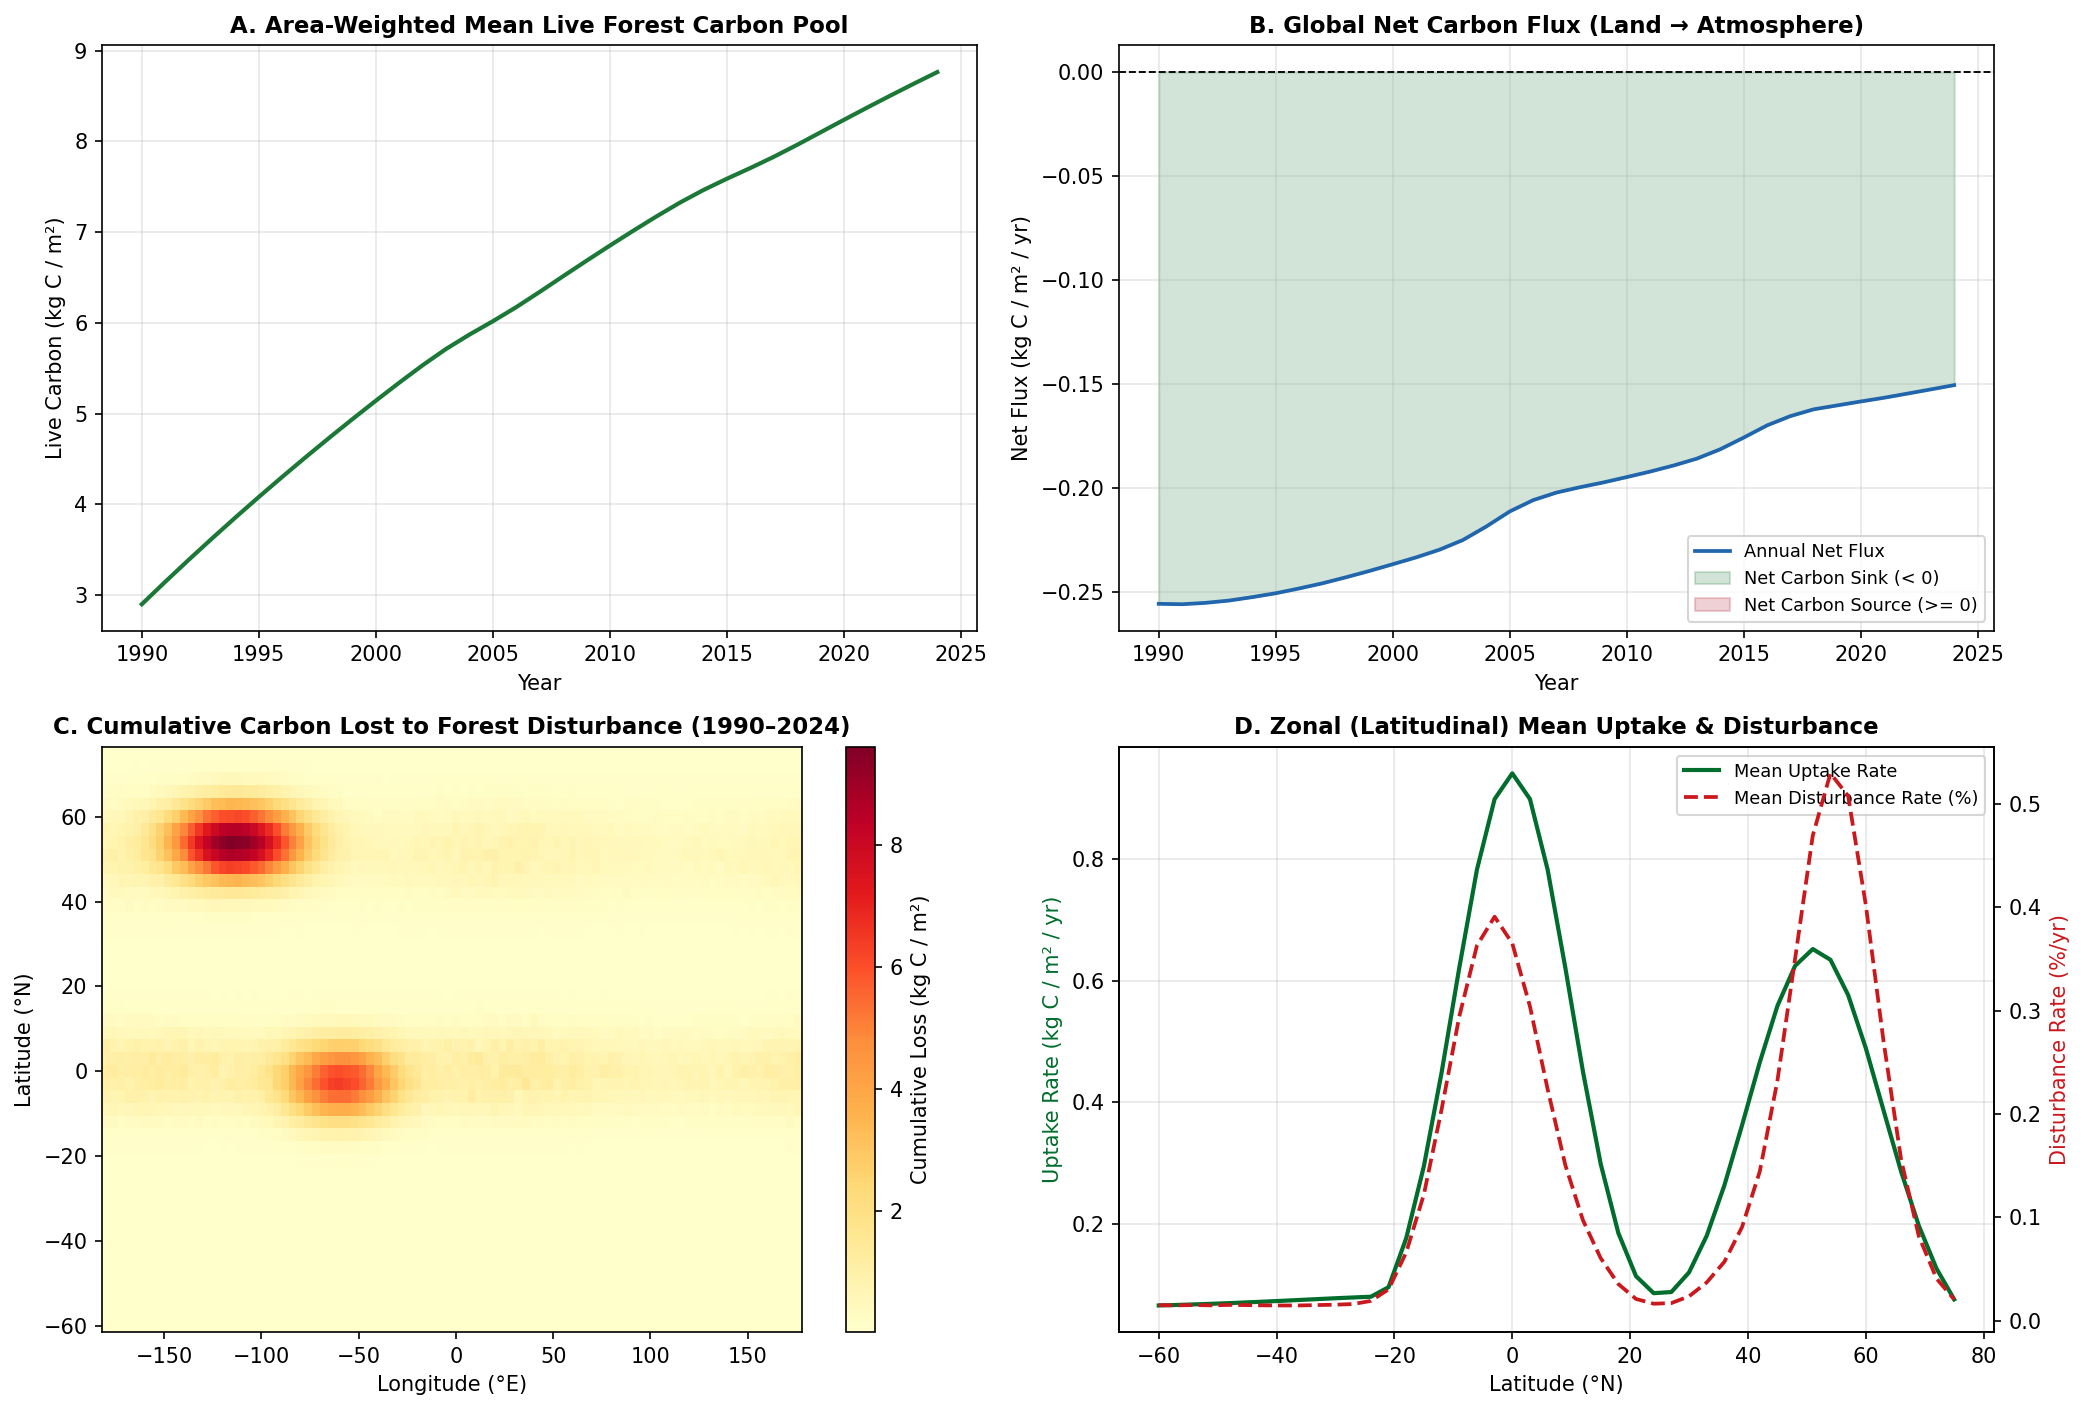

Mean global net flux (negative = uptake): -0.2058 kg C/m^2/yr
Max cumulative disturbance loss: 9.61 kg C/m^2 at lat=54.0, lon=-116.0
Max discrete Laplacian magnitude on disturbance loss: 2.420


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import laplace

# ==============================================================================
# 1. CONSTRUCT SYNTHETIC / BENCHMARK GRIDDED FOREST-CLIMATE DATASET
#    Dimensions: (time, lat, lon) -> Monthly steps over 35 years (1990-2024)
# ==============================================================================
rng = np.random.default_rng(2026)

dates = pd.date_range("1990-01-01", "2024-12-01", freq="MS")
n_time = len(dates)
years_elapsed = np.arange(n_time) / 12.0

lat = np.linspace(-60.0, 75.0, 46)      # 3-degree latitude grid (-60 to +75 N)
lon = np.linspace(-180.0, 176.0, 90)    # 4-degree longitude grid
LAT, LON = np.meshgrid(lat, lon, indexing="ij")

# Forest cover fraction mask (higher in tropical & temperate/boreal forest belts)
tropical_belt = np.exp(-((LAT - 0.0) / 14.0) ** 2)
temperate_boreal_belt = np.exp(-((LAT - 52.0) / 16.0) ** 2)
land_wave = 0.5 + 0.5 * np.cos(np.deg2rad(LON - 20.0)) * np.sin(np.deg2rad(LON + 60.0))
forest_mask = np.clip(
    (0.65 * tropical_belt + 0.55 * temperate_boreal_belt) * (0.45 + 0.55 * land_wave),
    0.05,
    0.95,
)

# Temperature anomaly (deg C) with long-term warming + seasonal cycle + noise
t_3d = years_elapsed[:, None, None]
lat_3d = LAT[None, :, :]
lon_3d = LON[None, :, :]
fmask_3d = forest_mask[None, :, :]

temp_anomaly = (
    0.032 * t_3d * (1.0 + 0.25 * np.abs(np.sin(np.deg2rad(lat_3d))))
    + 6.0 * np.sin(np.deg2rad(lat_3d)) * np.cos(2.0 * np.pi * t_3d - np.deg2rad(lon_3d) / 10.0)
    + rng.normal(0.0, 0.35, size=(n_time, len(lat), len(lon)))
)

# Baseline forest carbon uptake rate (kg C / m^2 / yr), modulated by CO2 fertilization
# and heat stress at high temperature anomalies
co2_fertilization = 1.0 + 0.0045 * t_3d
heat_stress = np.exp(-0.08 * np.maximum(temp_anomaly - 1.5, 0.0) ** 2)
seasonal_uptake = 0.65 + 0.35 * np.cos(2.0 * np.pi * t_3d - np.pi / 2.0)

uptake_rate = (
    2.4
    * fmask_3d
    * np.maximum(seasonal_uptake, 0.15)
    * co2_fertilization
    * heat_stress
)  # kg C / m^2 / yr

# Disturbance intensity d(t, lat, lon) in [0, 1] representing fractional live-carbon
# loss per year during localized climate/disturbance episodes (e.g., droughts/fires)
disturbance_rate = np.zeros((n_time, len(lat), len(lon)))

# Episode 1: Tropical forest disturbance around year 15 (2005)
ep1_spatial = np.exp(-(((LAT - (-4.0)) / 10.0) ** 2 + ((LON - (-60.0)) / 25.0) ** 2))
ep1_time = np.exp(-0.5 * ((years_elapsed - 15.0) / 1.2) ** 2)[:, None, None]
disturbance_rate += 0.22 * ep1_time * ep1_spatial[None, :, :]

# Episode 2: Boreal/temperate disturbance around year 26 (2016)
ep2_spatial = np.exp(-(((LAT - 55.0) / 9.0) ** 2 + ((LON - (-110.0)) / 30.0) ** 2))
ep2_time = np.exp(-0.5 * ((years_elapsed - 26.0) / 1.5) ** 2)[:, None, None]
disturbance_rate += 0.25 * ep2_time * ep2_spatial[None, :, :]

# Background sporadic disturbance noise scaled by forest cover
disturbance_rate += np.clip(
    rng.gamma(shape=0.15, scale=0.02, size=(n_time, len(lat), len(lon))) * fmask_3d,
    0.0,
    0.35,
)

# Package into an Xarray Dataset
ds = xr.Dataset(
    {
        "temp_anomaly": (("time", "lat", "lon"), temp_anomaly),
        "uptake_rate": (("time", "lat", "lon"), uptake_rate),
        "disturbance_rate": (("time", "lat", "lon"), disturbance_rate),
        "forest_mask": (("lat", "lon"), forest_mask),
    },
    coords={"time": dates, "lat": lat, "lon": lon},
)

# ==============================================================================
# 2. VECTORIZED TWO-POOL CARBON ODE INTEGRATION ACROSS ALL GRID CELLS
#    d(Cv)/dt = Uptake(t) - Disturbance(t)*Cv - k_mort*Cv
#    d(Cd)/dt = Disturbance(t)*Cv + k_mort*Cv - k_decomp*Cd
#    Net Biome Exchange (NBE) = k_decomp*Cd - Uptake(t)  (negative => net sink)
# ==============================================================================
dt = 1.0 / 12.0  # Monthly step in years

Cv = np.zeros_like(uptake_rate)  # Live forest carbon pool (kg C / m^2)
Cd = np.zeros_like(uptake_rate)  # Deadwood/litter carbon pool (kg C / m^2)
NBE = np.zeros_like(uptake_rate) # Net carbon flux to atmosphere (kg C / m^2 / yr)

# Initial equilibrium pools
k_mort = 0.025   # Baseline natural mortality rate (1/yr)
k_decomp = 0.12  # Litter/deadwood decomposition rate (1/yr)

cv_curr = 8.0 * forest_mask + 1.0
cd_curr = (k_mort * cv_curr) / k_decomp

for idx in range(n_time):
    u_step = uptake_rate[idx]
    d_step = disturbance_rate[idx]

    # Forward/semi-implicit Euler step across all (lat, lon) grid cells simultaneously
    live_loss = (d_step + k_mort) * cv_curr
    cv_next = np.maximum(cv_curr + dt * (u_step - live_loss), 0.0)

    dead_gain = live_loss
    dead_loss = k_decomp * cd_curr
    cd_next = np.maximum(cd_curr + dt * (dead_gain - dead_loss), 0.0)

    # Net flux from land to atmosphere: decomposition release minus gross uptake
    nbe_step = dead_loss - u_step

    Cv[idx] = cv_next
    Cd[idx] = cd_next
    NBE[idx] = nbe_step

    cv_curr, cd_curr = cv_next, cd_next

ds["live_carbon"] = (("time", "lat", "lon"), Cv)
ds["dead_carbon"] = (("time", "lat", "lon"), Cd)
ds["net_flux_to_atm"] = (("time", "lat", "lon"), NBE)

# ==============================================================================
# 3. AREA-WEIGHTED AGGREGATION & SPATIAL LAPLACIAN SMOOTHING DIAGNOSTIC
# ==============================================================================
cell_weights = xr.DataArray(
    np.cos(np.deg2rad(ds["lat"].values)),
    dims=("lat",),
    coords={"lat": ds["lat"]},
)

# Annual mean fluxes and pools
annual_nbe = ds["net_flux_to_atm"].resample(time="YE").mean("time")
annual_live_c = ds["live_carbon"].resample(time="YE").mean("time")
annual_dist = ds["disturbance_rate"].resample(time="YE").mean("time")

global_nbe_series = annual_nbe.weighted(cell_weights).mean(dim=("lat", "lon"))
global_live_c_series = annual_live_c.weighted(cell_weights).mean(dim=("lat", "lon"))

# Cumulative disturbance impact map (total live carbon lost to disturbance over period)
disturbance_loss_map = (ds["disturbance_rate"] * ds["live_carbon"] * dt).sum(dim="time")

# Discrete spatial Laplacian of cumulative disturbance loss
laplacian_dist_loss = laplace(disturbance_loss_map.values)

# ==============================================================================
# 4. MULTI-PANEL VISUALIZATION & QUANTITATIVE SUMMARY
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5), dpi=150)

# Panel A: Global Live Forest Carbon Pool Over Time
yr_axis = pd.to_datetime(global_live_c_series["time"].values).year
axes[0, 0].plot(yr_axis, global_live_c_series.values, color="#1b7837", linewidth=2)
axes[0, 0].set_title("A. Area-Weighted Mean Live Forest Carbon Pool", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Live Carbon (kg C / m²)")
axes[0, 0].grid(alpha=0.3)

# Panel B: Global Net Land-to-Atmosphere Flux (Negative = Net Carbon Sink)
axes[0, 1].plot(yr_axis, global_nbe_series.values, color="#2166ac", linewidth=1.8, label="Annual Net Flux")
axes[0, 1].axhline(0.0, color="black", linestyle="--", linewidth=0.9)
axes[0, 1].fill_between(
    yr_axis,
    global_nbe_series.values,
    0.0,
    where=(global_nbe_series.values < 0),
    interpolate=True,
    alpha=0.2,
    color="#1b7837",
    label="Net Carbon Sink (< 0)",
)
axes[0, 1].fill_between(
    yr_axis,
    global_nbe_series.values,
    0.0,
    where=(global_nbe_series.values >= 0),
    interpolate=True,
    alpha=0.2,
    color="#b2182b",
    label="Net Carbon Source (>= 0)",
)
axes[0, 1].set_title("B. Global Net Carbon Flux (Land → Atmosphere)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Year")
axes[0, 1].set_ylabel("Net Flux (kg C / m² / yr)")
axes[0, 1].legend(fontsize=8.5)
axes[0, 1].grid(alpha=0.3)

# Panel C: Cumulative Disturbance Carbon Loss Map
im_c = axes[1, 0].pcolormesh(
    ds["lon"].values,
    ds["lat"].values,
    disturbance_loss_map.values,
    cmap="YlOrRd",
    shading="auto",
)
plt.colorbar(im_c, ax=axes[1, 0], label="Cumulative Loss (kg C / m²)")
axes[1, 0].set_title("C. Cumulative Carbon Lost to Forest Disturbance (1990–2024)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Longitude (°E)")
axes[1, 0].set_ylabel("Latitude (°N)")

# Panel D: Latitudinal Profile of Mean Uptake vs Disturbance
lat_mean_uptake = ds["uptake_rate"].mean(dim=("time", "lon")).values
lat_mean_dist = (ds["disturbance_rate"] * 100.0).mean(dim=("time", "lon")).values
ax_d1 = axes[1, 1]
ax_d2 = ax_d1.twinx()

l1, = ax_d1.plot(ds["lat"].values, lat_mean_uptake, color="#006d2c", linewidth=2, label="Mean Uptake Rate")
l2, = ax_d2.plot(ds["lat"].values, lat_mean_dist, color="#cb181d", linewidth=1.8, linestyle="--", label="Mean Disturbance Rate (%)")

ax_d1.set_title("D. Zonal (Latitudinal) Mean Uptake & Disturbance", fontsize=11, fontweight="bold")
ax_d1.set_xlabel("Latitude (°N)")
ax_d1.set_ylabel("Uptake Rate (kg C / m² / yr)", color="#006d2c")
ax_d2.set_ylabel("Disturbance Rate (%/yr)", color="#cb181d")
ax_d1.grid(alpha=0.3)

lines = [l1, l2]
labels = [line.get_label() for line in lines]
ax_d1.legend(lines, labels, loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.savefig("spatiotemporal_forest_carbon_disturbance.png")
plt.show()

# Print summary metrics
peak_flat_idx = int(np.argmax(disturbance_loss_map.values))
peak_lat_idx, peak_lon_idx = np.unravel_index(peak_flat_idx, disturbance_loss_map.shape)
print(f"Mean global net flux (negative = uptake): {float(global_nbe_series.mean().values):.4f} kg C/m^2/yr")
print(
    f"Max cumulative disturbance loss: {disturbance_loss_map.values[peak_lat_idx, peak_lon_idx]:.2f} kg C/m^2 "
    f"at lat={ds['lat'].values[peak_lat_idx]:.1f}, lon={ds['lon'].values[peak_lon_idx]:.1f}"
)
print(f"Max discrete Laplacian magnitude on disturbance loss: {np.max(np.abs(laplacian_dist_loss)):.3f}")